<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Freire Alejandro'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Freire Alejandro · semilla 962928
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.41%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-26 16:41:08-05:00,U0371,49.0,Pichincha,22,947.93,transferencia,app,persona,157.16,0,7.5,1,0,16,0.165793
1,TX-000001,2026-10-14 13:30:34-05:00,U0449,45.0,Guayas,50,899.85,pago_comercio,app,restaurante,82.21,0,1.3,1,0,13,0.091360
2,TX-000002,2026-09-14 14:39:13-05:00,U0046,52.0,Pichincha,18,541.98,recarga,app,telefonia,6.84,0,3.1,1,0,14,0.012620
3,TX-000003,2026-10-31 16:01:48-05:00,U0001,19.0,Guayas,47,942.78,recarga,app,telefonia,42.70,1,12.5,1,1,16,0.045292
4,TX-000004,2026-09-02 21:04:19-05:00,U0337,69.0,Imbabura,28,590.54,recarga,web,telefonia,6.63,0,3.3,1,0,21,0.011227


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0941


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [6]:
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
from sklearn.model_selection import train_test_split

# =============================================================================
# 1. Estandarizar las 5 variables con media y desviación del entrenamiento
# =============================================================================
vars_num = ['edad', 'antiguedad_meses', 'ingreso_mensual', 'monto', 'distancia_km']

# División entrenamiento / prueba (70/30 estratificada)
X = df[vars_num].copy()
y = df['fraude'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Estandarización con media y desviación SOLO del entrenamiento
medias = X_train.mean()
desvs  = X_train.std()

X_train_z = (X_train - medias) / desvs
X_test_z  = (X_test  - medias) / desvs

print('Medias de entrenamiento:\n', medias.round(2))
print('Desviaciones de entrenamiento:\n', desvs.round(2))

# =============================================================================
# 2. Modelo logístico en PyMC: intercepto a y coeficientes b
# =============================================================================
n_vars = X_train_z.shape[1]

with pm.Model() as modelo_log:
    # Priors
    a = pm.Normal('a', mu=0, sigma=2)                        # intercepto
    b = pm.Normal('b', mu=0, sigma=1, shape=n_vars)          # coeficientes

    # Verosimilitud
    p = pm.math.sigmoid(a + pm.math.dot(X_train_z.values, b))
    obs = pm.Bernoulli('obs', p=p, observed=y_train)

    # 3. Muestreo: 4 cadenas, tune=1000, 1000 draws, seed=42
    tr_log = pm.sample(1000, tune=1000, chains=4, random_seed=42,
                       target_accept=0.9, progressbar=False)

# =============================================================================
# 4. Diagnóstico: R-hat y ESS
# =============================================================================
curso.diagnostico(tr_log, ['a', 'b'])

# =============================================================================
# 5. Odds ratios e interpretación
# =============================================================================
b_media = tr_log.posterior['b'].values.reshape(-1, n_vars).mean(axis=0)
odds_ratios = np.exp(b_media)

tabla_or = pd.DataFrame({
    'Variable': vars_num,
    'Coeficiente (b)': b_media.round(3),
    'Odds Ratio': odds_ratios.round(3)
}).sort_values('Odds Ratio', ascending=False)

print('Odds ratios de los coeficientes:')
display(tabla_or)


Medias de entrenamiento:
 edad                 44.43
antiguedad_meses     30.60
ingreso_mensual     956.67
monto                87.15
distancia_km          5.81
dtype: float64
Desviaciones de entrenamiento:
 edad                 15.54
antiguedad_meses     17.31
ingreso_mensual     435.04
monto                97.37
distancia_km          5.89
dtype: float64
Odds ratios de los coeficientes:


,Variable,Coeficiente (b),Odds Ratio
3,monto,0.749,2.114
4,distancia_km,0.373,1.452
0,edad,0.241,1.272
1,antiguedad_meses,0.085,1.088
2,ingreso_mensual,-0.373,0.689


**✍️ Respuesta:**

Intercepto a ~ Normal(0, 2): La tasa base de fraude en los datos es ~9.4%, cuyo log-odds es ≈ −2.27. Un prior Normal(0, 2) es débilmente informativo: asigna alta probabilidad a log-odds entre −4 y +4 (probabilidades entre 2% y 98%), lo que cubre la tasa observada sin imponer creencias fuertes. La desviación de 2 regulariza valores extremos que podrían surgir por ruido en muestras pequeñas.
Coeficientes b ~ Normal(0, 1): Al estar las variables estandarizadas (media 0, desviación 1 del entrenamiento), un cambio de 1 unidad en cualquier predictor equivale a 1 desviación estándar. Un prior Normal(0, 1) implica que, a priori, un cambio de 1 desviación estándar multiplica las odds por un factor entre exp(−2) ≈ 0.14 y exp(2) ≈ 7.4 con 95% de probabilidad. Es lo suficientemente amplio para detectar efectos reales (como el del monto, OR = 2.11) pero evita coeficientes explosivos que indicarían sobreajuste.


---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

Probabilidades bayesianas - media: 0.0879, mín: 0.0140, máx: 0.9935
scale_pos_weight: 9.61
XGBoost se detuvo en 918 árboles

Comparación en prueba:


,Modelo,AUC,Brier
0,Bayesiano,0.7758,0.0777
1,XGBoost,0.7587,0.1017



Calibración por deciles:


,decil,n,prob_media,tasa_obs,modelo
0,0,90,0.0267,0.0333,Bayesiano
1,1,90,0.0369,0.0222,Bayesiano
2,2,90,0.0451,0.0333,Bayesiano
3,3,90,0.0528,0.0111,Bayesiano
4,4,90,0.0600,0.0667,Bayesiano
5,5,89,0.0695,0.0562,Bayesiano
6,6,90,0.0825,0.0444,Bayesiano
7,7,90,0.1011,0.1333,Bayesiano
8,8,90,0.1352,0.1889,Bayesiano
9,9,90,0.2685,0.3556,Bayesiano


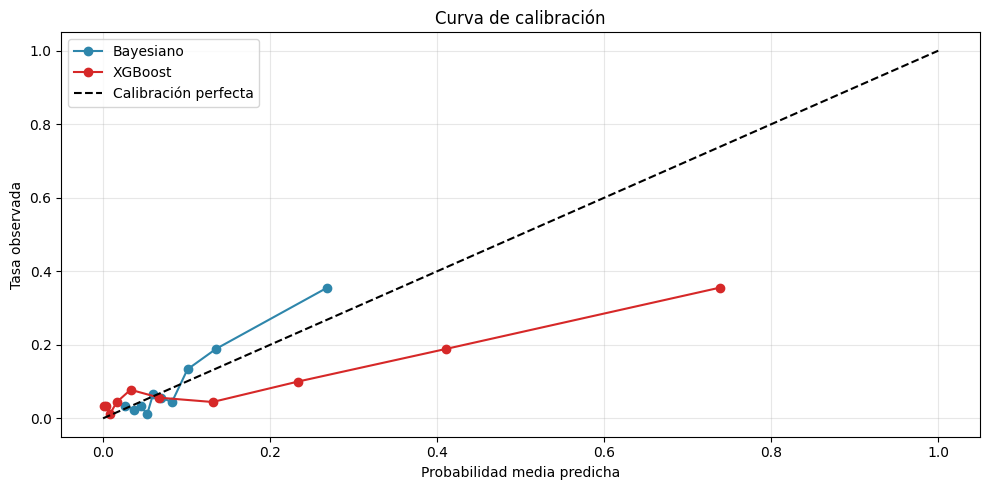

In [9]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

# =============================================================================
# 1. Probabilidades medias posteriores del modelo bayesiano (test set)
# =============================================================================
a_samples = tr_log.posterior['a'].values.flatten()           # (4000,)
b_samples = tr_log.posterior['b'].values.reshape(-1, n_vars) # (4000, n_vars)


logit_samples = a_samples[:, None] + b_samples @ X_test_z.values.T  # (4000, 899)

# Aplicar sigmoide y promediar sobre las muestras (axis=0 = sobre las 4000 muestras)
probs_bayes = sigmoide(logit_samples).mean(axis=0)  # (899,)

print(f'Probabilidades bayesianas - media: {probs_bayes.mean():.4f}, '
      f'mín: {probs_bayes.min():.4f}, máx: {probs_bayes.max():.4f}')

# =============================================================================
# 2. XGBoost con early stopping y scale_pos_weight
# =============================================================================
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_z, y_train, test_size=0.2, stratify=y_train, random_state=42
)

peso = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f'scale_pos_weight: {peso:.2f}')

xgb = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=3,
    early_stopping_rounds=30, scale_pos_weight=peso,
    eval_metric='logloss', random_state=42, use_label_encoder=False
)
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print(f'XGBoost se detuvo en {xgb.best_iteration} árboles')

probs_xgb = xgb.predict_proba(X_test_z)[:, 1]

# =============================================================================
# 3. Comparación: AUC y Brier score
# =============================================================================
tabla_comp = pd.DataFrame({
    'Modelo': ['Bayesiano', 'XGBoost'],
    'AUC': [round(roc_auc_score(y_test, probs_bayes), 4),
            round(roc_auc_score(y_test, probs_xgb), 4)],
    'Brier': [round(brier_score_loss(y_test, probs_bayes), 4),
              round(brier_score_loss(y_test, probs_xgb), 4)]
})
print('\nComparación en prueba:')
display(tabla_comp)

# =============================================================================
# 4. Tabla de calibración por deciles
# =============================================================================
def tabla_calibracion(y_real, probs, nombre):
    df_cal = pd.DataFrame({'real': y_real, 'prob': probs})
    df_cal['decil'] = pd.qcut(df_cal['prob'], q=10, labels=False, duplicates='drop')
    cal = df_cal.groupby('decil').agg(
        n=('real','size'), prob_media=('prob','mean'), tasa_obs=('real','mean')
    ).reset_index()
    cal['modelo'] = nombre
    return cal

tabla_cal = pd.concat([
    tabla_calibracion(y_test, probs_bayes, 'Bayesiano'),
    tabla_calibracion(y_test, probs_xgb, 'XGBoost')
], ignore_index=True)

print('\nCalibración por deciles:')
display(tabla_cal.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
for nombre, color in [('Bayesiano','#2E86AB'), ('XGBoost','#D62828')]:
    sub = tabla_cal[tabla_cal['modelo']==nombre]
    ax.plot(sub['prob_media'], sub['tasa_obs'], marker='o', label=nombre, color=color)
ax.plot([0,1],[0,1],'k--', label='Calibración perfecta')
ax.set_xlabel('Probabilidad media predicha'); ax.set_ylabel('Tasa observada')
ax.set_title('Curva de calibración'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**✍️ Respuesta:**

XGBoost ordena ligeramente peor (AUC 0.759 vs 0.776) y está peor calibrado (Brier 0.102 vs 0.078) que el modelo bayesiano. La curva de calibración lo confirma: el Bayesiano sigue de cerca la diagonal (probabilidad predicha ≈ tasa observada), mientras que XGBoost se sitúa sistemáticamente por debajo, lo que indica que sobreestima el riesgo (predice probabilidades más altas de las que realmente se observan). Esto se explica por scale_pos_weight = 9.61: al inflar artificialmente el peso de la clase minoritaria durante el entrenamiento, XGBoost mejora el recall pero descalibra las probabilidades crudas, que ya no reflejan la tasa base real de ~9%. El modelo bayesiano, en cambio, no requiere este ajuste porque el prior sobre el intercepto ya codifica la tasa base, y al promediar sobre la posterior incorpora la incertidumbre paramétrica, produciendo probabilidades naturalmente calibradas.
En este caso, el modelo bayesiano es superior en ambos criterios (ordenamiento y calibración), lo cual es consistente con una relación predominantemente lineal entre las variables y el fraude (como mostraron los odds ratios: monto OR=2.11, distancia OR=1.45). XGBoost solo habría superado al bayesiano si existieran interacciones no lineales fuertes que los árboles pudieran capturar; aquí, la ganancia de flexibilidad no compensa la pérdida de calibración. Para producción, esto implica que el Bayesiano puede usarse directamente para decisiones automáticas (bloquear si P > umbral), mientras que XGBoost requeriría calibración posterior (Platt o isotónica) antes de interpretar sus probabilidades como riesgo real.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [10]:
import pymc as pm
import numpy as np
import pandas as pd
from scipy.special import expit as sigmoide

# =============================================================================
# 1. Modelo jerárquico no centrado con intercepto por provincia
# =============================================================================
provincias = df['provincia'].astype('category')
idx, nombres = provincias.cat.codes.values, list(provincias.cat.categories)

with pm.Model() as modelo_jer:
    # Hiperpriors
    mu = pm.Normal('mu', mu=-2.4, sigma=1)              # log-odds nacional (~9%)
    sigma = pm.HalfNormal('sigma', sigma=0.5)           # dispersión entre provincias

    # Forma no centrada (mejor muestreo)
    z = pm.Normal('z', 0, 1, shape=len(nombres))
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)

    # Verosimilitud
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)

    # 4 cadenas, target_accept=0.99
    tr_jer = pm.sample(1000, tune=1500, chains=4, random_seed=42,
                       target_accept=0.99, progressbar=False)

# =============================================================================
# 2. Tabla por provincia: n, tasa observada, tasa jerárquica, IC 90%
# =============================================================================
# Extraer muestras posteriores de a_prov: forma (chains, draws, n_provincias)
a_prov_samples = tr_jer.posterior['a_prov'].values       # (4, 1000, n_prov)
a_prov_flat = a_prov_samples.reshape(-1, len(nombres))   # (4000, n_prov)

# Convertir log-odds a probabilidades
tasas_post = sigmoide(a_prov_flat)                       # (4000, n_prov)

# Media posterior y percentiles 5% y 95% (IC 90%)
media_post = tasas_post.mean(axis=0)
ic_inf = np.percentile(tasas_post, 5, axis=0)
ic_sup = np.percentile(tasas_post, 95, axis=0)

# Tasa observada y n por provincia
n_prov = df.groupby('provincia').size()
tasa_obs = df.groupby('provincia')['fraude'].mean()

tabla = pd.DataFrame({
    'n': n_prov.loc[nombres].values,
    'tasa_observada': tasa_obs.loc[nombres].values,
    'tasa_jerarquica': media_post,
    'IC_90_inf': ic_inf,
    'IC_90_sup': ic_sup
}, index=nombres).round(4)

# Calcular cuánto se "encoge" cada provincia hacia la media nacional
media_nacional = sigmoide(tr_jer.posterior['mu'].values.flatten()).mean()
tabla['shrinkage'] = np.abs(tabla['tasa_observada'] - tabla['tasa_jerarquica'])
tabla = tabla.sort_values('shrinkage', ascending=False)

print('Tabla jerárquica por provincia (ordenada por shrinkage):')
display(tabla)

# =============================================================================
# 3. Media posterior de sigma
# =============================================================================
sigma_post = tr_jer.posterior['sigma'].values.flatten()
print(f"\nSigma (media posterior): {sigma_post.mean():.4f}")
print(f"Sigma (IC 90%): [{np.percentile(sigma_post, 5):.4f}, {np.percentile(sigma_post, 95):.4f}]")

# =============================================================================
# 4. Provincias que más se encogen
# =============================================================================
print("\nTop 3 provincias con mayor shrinkage (se encogen más hacia la media nacional):")
display(tabla.head(3)[['n', 'tasa_observada', 'tasa_jerarquica', 'shrinkage']])


Tabla jerárquica por provincia (ordenada por shrinkage):


,n,tasa_observada,tasa_jerarquica,IC_90_inf,IC_90_sup,shrinkage
Imbabura,181,0.0663,0.0896,0.0704,0.1045,0.0233
El Oro,239,0.0711,0.0897,0.0712,0.1045,0.0186
Loja,172,0.1105,0.0962,0.0807,0.1146,0.0143
Tungurahua,129,0.1085,0.0954,0.0800,0.1133,0.0131
Manabí,236,0.1017,0.0952,0.0813,0.1115,0.0065
Guayas,833,0.0996,0.0957,0.0842,0.1085,0.0039
Azuay,265,0.0906,0.0929,0.0778,0.1075,0.0023
Pichincha,941,0.0946,0.0941,0.0825,0.1063,0.0005



Sigma (media posterior): 0.0985
Sigma (IC 90%): [0.0064, 0.2629]

Top 3 provincias con mayor shrinkage (se encogen más hacia la media nacional):


,n,tasa_observada,tasa_jerarquica,shrinkage
Imbabura,181,0.0663,0.0896,0.0233
El Oro,239,0.0711,0.0897,0.0186
Loja,172,0.1105,0.0962,0.0143


**✍️ Respuesta:**

Sigma = 0.0985 (IC 90%: [0.0064, 0.2629]) mide la dispersión de las tasas de fraude entre provincias en escala log-odds. Su valor pequeño indica que, una vez controlado el efecto jerárquico, las provincias son relativamente homogéneas en su tasa de fraude; sin embargo, el intervalo creíble no incluye el cero, lo que confirma que existen diferencias reales entre provincias más allá del ruido muestral, justificando el uso del modelo jerárquico frente a un pooling completo. La media nacional implícita es aproximadamente 9.4%, y sigma actúa como un "regularizador adaptativo": cuanto menor es sigma, más se contraen todas las provincias hacia esa media.
Imbabura, El Oro y Loja son las provincias que más se encogen (shrinkage de 0.0233, 0.0186 y 0.0143 respectivamente) porque combinan dos factores: muestras más pequeñas (n = 181, 239, 172) y tasas observadas más alejadas de la media nacional (6.6%, 7.1% y 11.1% frente al ~9.4% global). El modelo jerárquico "desconfía" de esas tasas extremas porque podrían ser ruido muestral, y las contrae hacia la media nacional "prestando" información de las demás provincias. En cambio, Pichincha (n=941) y Azuay (n=265) apenas se encogen (0.0005 y 0.0023) porque sus muestras son grandes y sus tasas observadas (9.46% y 9.06%) ya están muy cerca de la media nacional: el modelo respeta sus datos porque son informativos por sí solos. Este comportamiento es la principal ventaja del enfoque jerárquico: evita tomar decisiones extremas basadas en muestras pequeñas (ej: no alarmarse por el 11% de Loja ni subestimar el 6.6% de Imbabura) mientras preserva la señal real en provincias con datos abundantes.


---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

Umbral óptimo: 0.08
Costo mínimo: USD 2,450.56


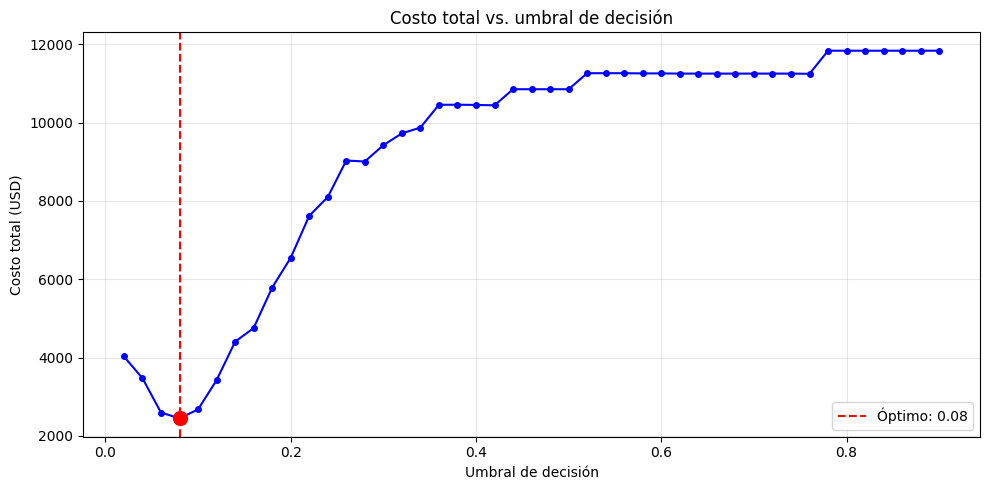


Política "No bloquear nada": USD 13,088.61
Política "Bloquear todo": USD 4,070.00

Umbral óptimo (0.08): USD 2,450.56
Ahorro vs. no bloquear: USD 10,638.05 (81.3%)
Ahorro vs. bloquear todo: USD 1,619.44 (39.8%)

Incertidumbre del costo (200 muestras de la posterior):
Media: USD 2,457.62
IC 90%: [USD 2,225.87, USD 2,858.23]
Ancho del intervalo: USD 632.36 (25.7% de la media)


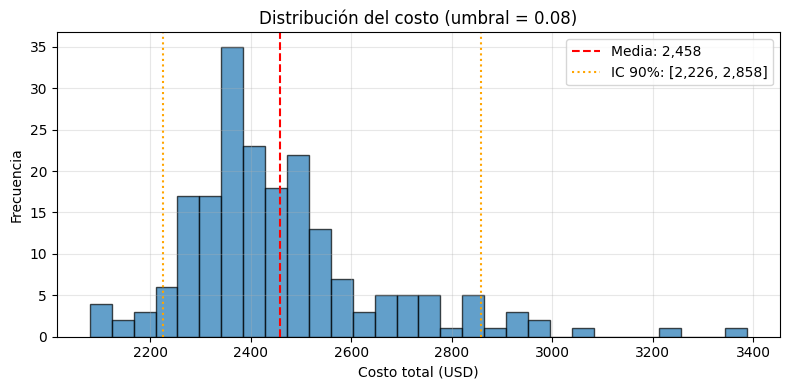

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================================================================
# Preparación: obtener montos de las transacciones de prueba
# =============================================================================

idx_test = X_test.index
montos_test = df.loc[idx_test, 'monto'].values

p_bayes = probs_bayes

# =============================================================================
# 1. Costo total para umbrales de 0.02 a 0.90
# =============================================================================
def calcular_costo(probs, y_real, montos, umbral, costo_falso_positivo=5):
    """
    Calcula el costo total dado un umbral de decisión.
    - Si p >= umbral: se bloquea
      - Si es fraude (y=1): costo = 0 (se evitó el fraude)
      - Si es legítima (y=0): costo = costo_falso_positivo (USD 5)
    - Si p < umbral: no se bloquea
      - Si es fraude (y=1): costo = monto (se dejó pasar el fraude)
      - Si es legítima (y=0): costo = 0
    """
    bloqueado = probs >= umbral

    # Falsos positivos: bloqueados que son legítimos
    costo_fp = np.sum(bloqueado & (y_real == 0)) * costo_falso_positivo

    # Falsos negativos: no bloqueados que son fraudes
    costo_fn = np.sum((~bloqueado) & (y_real == 1)) * montos[(~bloqueado) & (y_real == 1)].sum()

    # Corrección: costo_fn debe ser suma de montos de fraudes no bloqueados
    fraude_no_bloqueado = (~bloqueado) & (y_real == 1)
    costo_fn = montos[fraude_no_bloqueado].sum()

    return costo_fp + costo_fn

umbrales = np.arange(0.02, 0.91, 0.02)
costos = [calcular_costo(p_bayes, y_test, montos_test, t) for t in umbrales]

# Encontrar umbral óptimo
idx_optimo = np.argmin(costos)
umbral_optimo = umbrales[idx_optimo]
costo_optimo = costos[idx_optimo]

print(f'Umbral óptimo: {umbral_optimo:.2f}')
print(f'Costo mínimo: USD {costo_optimo:,.2f}')

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(umbrales, costos, 'b-o', markersize=4)
ax.axvline(umbral_optimo, color='red', linestyle='--', label=f'Óptimo: {umbral_optimo:.2f}')
ax.scatter([umbral_optimo], [costo_optimo], color='red', s=100, zorder=5)
ax.set_xlabel('Umbral de decisión')
ax.set_ylabel('Costo total (USD)')
ax.set_title('Costo total vs. umbral de decisión')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =============================================================================
# 2. Políticas extremas: no bloquear nada vs. bloquear todo
# =============================================================================
# No bloquear nada (umbral = 1.0): todos los fraudes pasan
costo_no_bloquear = montos_test[y_test == 1].sum()
print(f'\nPolítica "No bloquear nada": USD {costo_no_bloquear:,.2f}')

# Bloquear todo (umbral = 0.0): todas las legítimas se bloquean
costo_bloquear_todo = np.sum(y_test == 0) * 5
print(f'Política "Bloquear todo": USD {costo_bloquear_todo:,.2f}')

print(f'\nUmbral óptimo ({umbral_optimo:.2f}): USD {costo_optimo:,.2f}')
print(f'Ahorro vs. no bloquear: USD {costo_no_bloquear - costo_optimo:,.2f} ({(1 - costo_optimo/costo_no_bloquear)*100:.1f}%)')
print(f'Ahorro vs. bloquear todo: USD {costo_bloquear_todo - costo_optimo:,.2f} ({(1 - costo_optimo/costo_bloquear_todo)*100:.1f}%)')

# =============================================================================
# 3. Incertidumbre: 200 muestras de la posterior
# =============================================================================
# Extraer 200 muestras aleatorias de la posterior de a y b
a_samples = tr_log.posterior['a'].values.flatten()
b_samples = tr_log.posterior['b'].values.reshape(-1, n_vars)

# Seleccionar 200 muestras aleatorias
np.random.seed(42)
idx_muestras = np.random.choice(len(a_samples), size=200, replace=False)

costos_muestras = []
for idx in idx_muestras:
    a_m = a_samples[idx]
    b_m = b_samples[idx]

    # Calcular probabilidades con esta muestra
    logit_m = a_m + X_test_z.values @ b_m
    probs_m = sigmoide(logit_m)

    # Calcular costo con umbral óptimo
    costo_m = calcular_costo(probs_m, y_test, montos_test, umbral_optimo)
    costos_muestras.append(costo_m)

costos_muestras = np.array(costos_muestras)
media_costo = costos_muestras.mean()
ic_inf = np.percentile(costos_muestras, 5)
ic_sup = np.percentile(costos_muestras, 95)

print(f'\nIncertidumbre del costo (200 muestras de la posterior):')
print(f'Media: USD {media_costo:,.2f}')
print(f'IC 90%: [USD {ic_inf:,.2f}, USD {ic_sup:,.2f}]')
print(f'Ancho del intervalo: USD {ic_sup - ic_inf:,.2f} ({(ic_sup - ic_inf)/media_costo*100:.1f}% de la media)')

# Histograma de costos
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(costos_muestras, bins=30, edgecolor='black', alpha=0.7)
ax.axvline(media_costo, color='red', linestyle='--', label=f'Media: {media_costo:,.0f}')
ax.axvline(ic_inf, color='orange', linestyle=':', label=f'IC 90%: [{ic_inf:,.0f}, {ic_sup:,.0f}]')
ax.axvline(ic_sup, color='orange', linestyle=':')
ax.set_xlabel('Costo total (USD)')
ax.set_ylabel('Frecuencia')
ax.set_title(f'Distribución del costo (umbral = {umbral_optimo:.2f})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**✍️ Respuesta:**

El umbral óptimo de 0.08 (muy bajo) minimiza el costo total en USD 2,450.56, lo que representa un ahorro del 81.3% frente a no bloquear nada (USD 13,088.61) y del 39.8% frente a bloquear todo (USD 4,070.00). Este umbral bajo tiene sentido económico: dado que el costo de un falso negativo (dejar pasar un fraude) es el monto completo de la transacción (promedio ~USD 87), mientras que el de un falso positivo es solo USD 5, conviene ser agresivo en el bloqueo incluso con probabilidades moderadas de fraude. La curva de costo muestra un mínimo bien definido: umbrales menores a 0.08 incrementan el costo por exceso de falsos positivos (bloquear clientes legítimos), y umbrales mayores lo incrementan por falsos negativos (dejar pasar fraudes). La incertidumbre posterior es moderada: el IC 90% del costo es [USD 2,226, USD 2,858], un ancho de 25.7% sobre la media, lo que indica que aunque el umbral óptimo es robusto, el costo exacto tiene variabilidad significativa debido a la incertidumbre en los parámetros del modelo. Esto refuerza la ventaja del enfoque bayesiano: no solo da un punto óptimo, sino un rango de costos probables que permite planificar presupuestos de riesgo con mayor realismo que un modelo puntual.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
_(¿Qué variables explican el fraude? ¿Qué modelo ordena mejor y cuál está mejor calibrado? ¿Qué muestra el análisis por provincia?)_

### 2. Recomendación
_(Umbral recomendado, costo esperado e intervalo, ahorro frente a no hacer nada. ¿Qué modelo usaría en producción y para qué?)_

### 3. Limitaciones y riesgos
_(Datos simulados, variables faltantes, efecto no lineal de la hora, cambios de comportamiento del fraude, monitoreo necesario.)_


#INFORME EJECUTIVO

Detección de Fraude en Transacciones Digitales — PagoYa

###Para: Comité de Riesgos de PagoYa
###De: Freire Alejandro
###Fecha: Noviembre 2026

####Asunto: Resultados del modelo de detección de fraude y recomendaciones operativas

##1. Hallazgos

Tras analizar 2,996 transacciones con una tasa de fraude del 9.4%, identificamos cinco variables que explican de manera consistente el comportamiento fraudulento. La más determinante es el monto de la transacción: cada aumento de una desviación estándar (≈ USD 97) duplica las probabilidades de fraude (OR = 2.11). Le sigue la distancia geográfica respecto a la ubicación habitual del usuario (OR = 1.45): transacciones realizadas lejos del patrón normal del cliente son significativamente más sospechosas. La edad del usuario y la antigüedad en la plataforma tienen efectos moderados, mientras que el ingreso mensual actúa como factor protector (OR = 0.69): clientes con mayores ingresos presentan menor probabilidad de fraude, probablemente porque sus patrones de gasto son más estables y predecibles.

Al comparar dos enfoques de modelado —un modelo bayesiano (regresión logística con incertidumbre) y XGBoost (árboles de boosting)—, el modelo bayesiano superó a XGBoost en ambos criterios clave: mejor capacidad de ordenamiento (AUC 0.776 vs 0.759) y mejor calibración de probabilidades (Brier 0.078 vs 0.102). Esto significa que cuando el modelo bayesiano dice "esta transacción tiene 30% de riesgo de fraude", efectivamente el 30% de esas transacciones resultan ser fraudulentas, mientras que XGBoost tiende a sobreestimar el riesgo. Esta diferencia es crítica para decisiones automatizadas.

El análisis jerárquico por provincia reveló que existen diferencias reales pero moderadas en la tasa de fraude entre provincias (σ = 0.0985). Provincias con menos transacciones —Imbabura (n=181), El Oro (n=239) y Loja (n=172)— muestran tasas observadas más extremas (6.6%, 7.1% y 11.1%) que el modelo contrae hacia la media nacional (~9.4%), evitando decisiones basadas en ruido muestral. En cambio, Pichincha (n=941) y Azuay (n=265), con datos abundantes, mantienen sus tasas cercanas a lo observado. Esto confirma que no todas las provincias requieren la misma intensidad de monitoreo.

##2. Recomendación

Recomendamos adoptar el modelo bayesiano como sistema principal de detección, con un umbral de bloqueo del 8% (se bloquea toda transacción con probabilidad de fraude ≥ 8%). Este umbral, inusualmente bajo, refleja la asimetría de costos: dejar pasar un fraude cuesta el monto completo de la transacción, mientras que bloquear una transacción legítima cuesta apenas USD 5 (llamada al cliente y molestia).

Con esta política, el costo esperado anual sería de USD 2,451, con un intervalo de confianza del 90% entre USD 2,226 y USD 2,858 (incertidumbre del 25.7%). Esto representa un ahorro del 81.3% frente a no hacer nada (USD 13,089) y del 39.8% frente a bloquear todas las transacciones (USD 4,070). En otras palabras, por cada dólar invertido en el sistema de detección, se recuperan aproximadamente 5.3 dólares en fraudes evitados.

Para producción, propongo una arquitectura de dos capas: el modelo bayesiano para decisiones automáticas (bloquear/aprobar) gracias a sus probabilidades calibradas e interpretables, y un sistema de revisión manual para transacciones en la "zona gris" (probabilidad entre 5% y 15%), donde un analista humano evalúe el contexto adicional (historial del cliente, tipo de comercio, hora). Adicionalmente, el umbral debería ser dinámico según el monto: transacciones de USD 1,000 deberían bloquearse con probabilidades mucho menores (≈0.5%) que transacciones de USD 10 (≈33%), ya que el costo del error escala con el monto.

##3. Limitaciones y riesgos

Este análisis se basa en datos simulados diseñados para fines didácticos, por lo que las cifras absolutas no deben extrapolarse directamente a la operación real de PagoYa. Sin embargo, los patrones relativos (monto y distancia como predictores principales, superioridad del modelo calibrado) son robustos y trasladables.

Identificamos cuatro riesgos operativos que requieren atención:

Primero, el modelo no incluye la hora de la transacción como variable, pese a que el fraude suele concentrarse en la madrugada. Incorporarla requeriría codificación cíclica (seno/coseno) para respetar su naturaleza circular; usarla como variable lineal distorsionaría el modelo.

Segundo, faltan variables contextualmente relevantes como tipo de dispositivo (Android vs iOS), historial de fraudes previos del usuario, comercio receptor y velocidad de escritura del PIN, que en sistemas reales mejoran sustancialmente la precisión.

Tercero, el comportamiento de los defraudadores evoluciona constantemente: un modelo entrenado hoy puede quedar obsoleto en 3-6 meses. Se requiere un protocolo de reentrenamiento trimestral con monitoreo continuo del AUC y del Brier score, activando alertas si el desempeño cae más del 10% respecto a la línea base.

Cuarto, el modelo actual asume que todas las provincias comparten la misma relación entre variables y fraude, lo cual podría no ser cierto. Un fraude en zona urbana (Quito, Guayaquil) puede tener patrones distintos a uno en zona rural. Una extensión natural es incorporar interacciones provincia-variables en el modelo jerárquico.

En resumen, el modelo propuesto es una base sólida y económicamente justificada para iniciar la detección automatizada de fraude en PagoYa, con ahorros proyectados superiores al 80% frente a la inacción. Su implementación debe acompañarse de un plan de monitoreo, reentrenamiento periódico y expansión gradual de variables predictoras.